# Example of the `aitlas` toolbox in the context of multi label image classification

This notebook shows a sample implementation of a multi label image classification using the `aitlas` toolbox using the AID multi label dataset.

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import AIDMultiLabelDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/AID_multilabel/train/images",
    "csv_file": "./data/AID_multilabel/train/multilabels.txt",
}
dataset = AIDMultiLabelDataset(dataset_config)

## Show images from the dataset

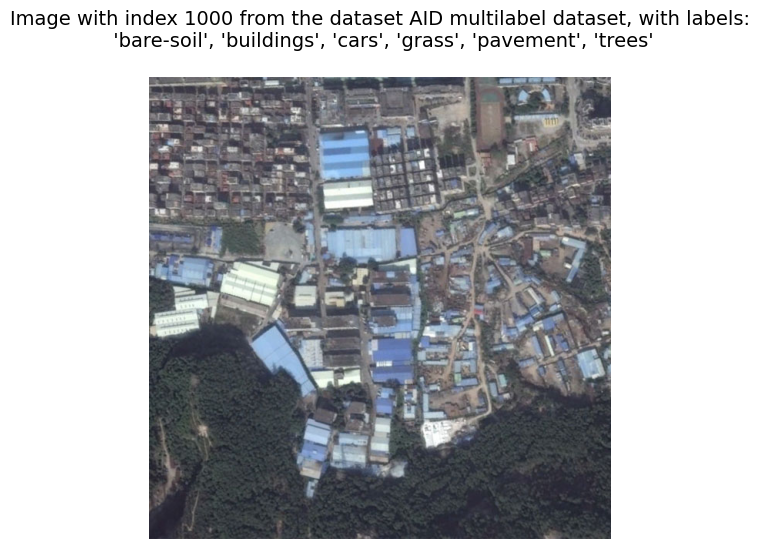

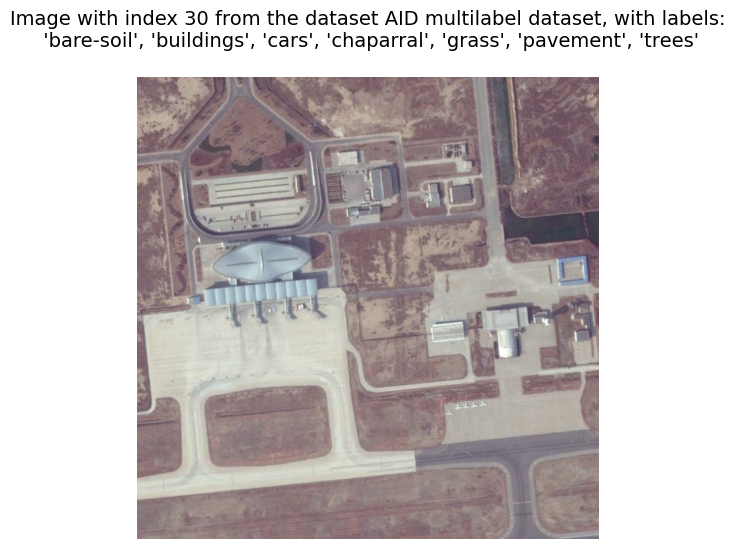

In [7]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)

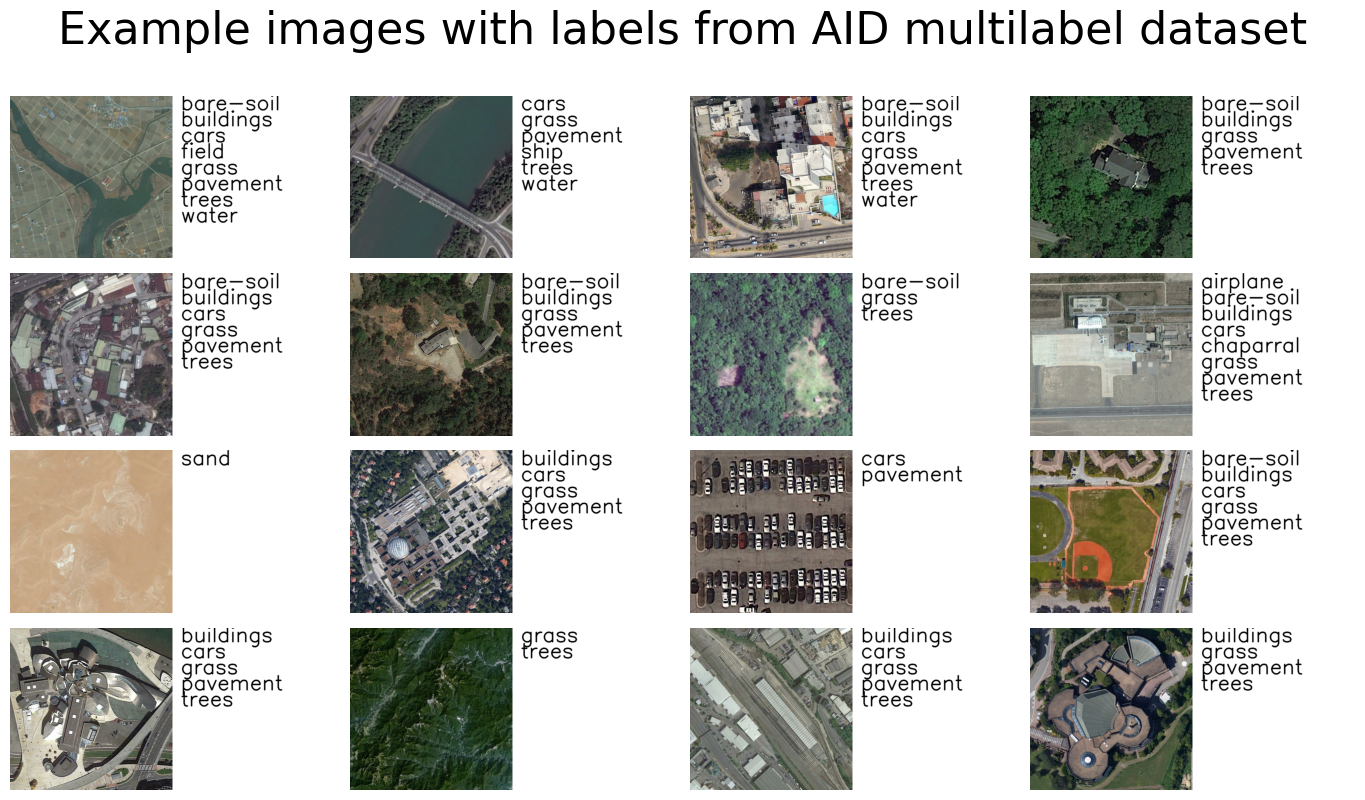

In [8]:
fig3 = dataset.show_batch(16)

## Inspect the data

In [9]:
dataset.show_samples()

,IMAGE\LABEL,airplane,bare-soil,buildings,cars,chaparral,court,dock,field,grass,mobile-home,pavement,sand,sea,ship,tanks,trees,water
0,airport_1,1,1,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0
1,airport_2,1,1,1,1,0,0,0,0,1,0,1,0,0,0,0,1,0
2,airport_3,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0
3,airport_4,1,1,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0
4,airport_5,1,1,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0
5,airport_6,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,1,0
6,airport_7,1,1,1,1,0,0,0,0,1,0,1,0,0,0,0,1,0
7,airport_8,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,1,0
8,airport_9,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,1,0
9,airport_10,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,1,0


In [10]:
dataset.data_distribution_table()

,Label,Count
1,airplane,79
2,bare-soil,1171
3,buildings,1744
4,cars,1617
5,chaparral,75
6,court,269
7,dock,221
8,field,175
9,grass,1829
10,mobile-home,1


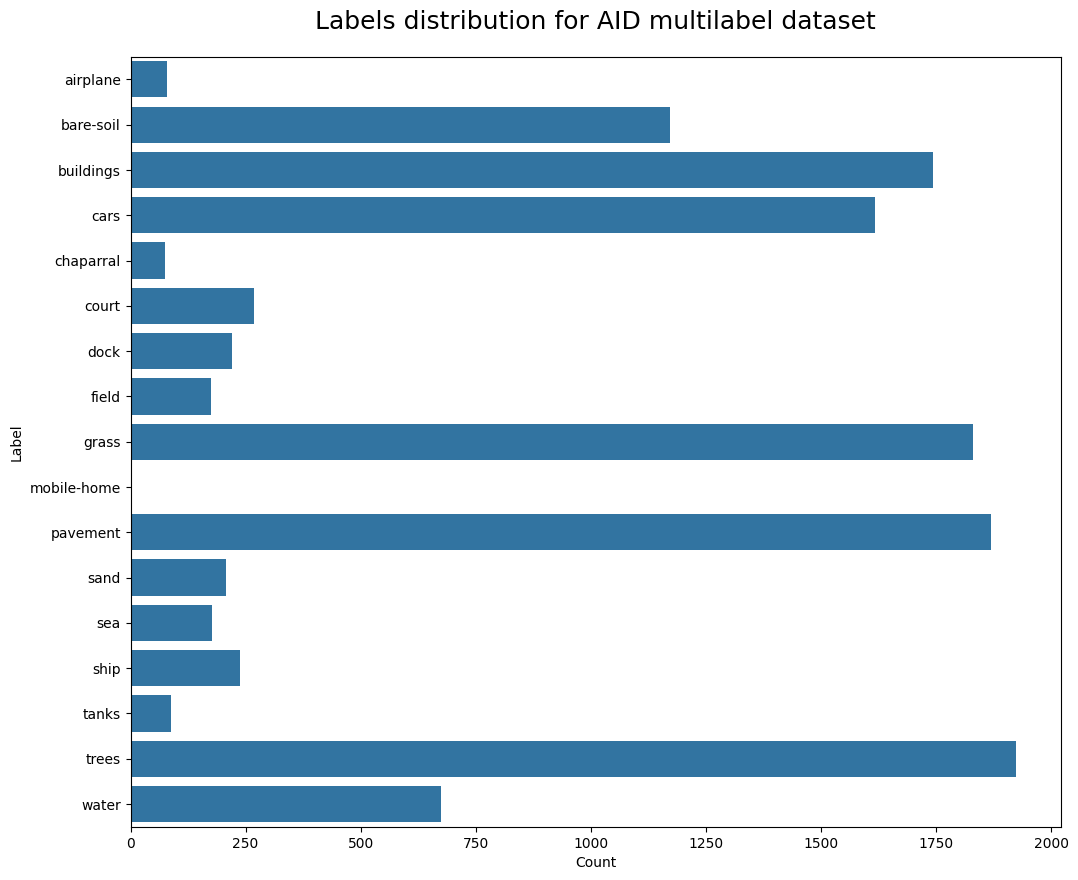

In [11]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/AID_multilabel/train/images",
    "csv_file": "./data/AID_multilabel/train/multilabels.txt",
}

train_dataset = AIDMultiLabelDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/AID_multilabel/test/images",
    "csv_file": "./data/AID_multilabel/test/multilabels.txt",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = AIDMultiLabelDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(2400, 600)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/AID_multilabel"
model_config = {
    "num_classes": 17,
    "learning_rate": 0.0001,
    "pretrained": True,
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [14]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-19 12:09:42,059 INFO Starting training.
training: 100%|██████████| 150/150 [00:05<00:00, 26.67it/s]
2026-08-19 12:09:47,722 INFO epoch: 1, time: 5, loss:  0.47587
testing on train set: 100%|██████████| 150/150 [00:04<00:00, 31.89it/s]
2026-08-19 12:09:53,420 INFO Accuracy:0.9279656862745098, Accuracy per Class:[0.96708333 0.80583333 0.91416667 0.90791667 0.96875    0.92916667
 0.92833333 0.9575     0.895      0.99958333 0.96       0.97708333
 0.9325     0.91916667 0.96375    0.92       0.82958333], Precision Micro:0.9060883063125216, Precision Macro:0.6957532085582206, Precision Weighted:0.8889172048185285, Precision per Class:[0.         0.7854251  0.93250844 0.91448931 0.         0.96261682
 0.85507246 0.93975904 0.8882324  0.         0.98364231 0.98717949
 1.         0.89090909 0.         0.92243902 0.76553106], Recall Micro:0.850287286558226, Recall Macro:0.4919477820131877, Recall Weighted:0.8502872865582263, Recall per Class:[0.         0.82835184 0.95068807 0.95238095 0.

0.07379158125241837

## Predictions

2026-08-19 12:11:38,851 INFO Loading checkpoint /home/dragik/data/experiments/AID_multilabel/checkpoint.pth.tar
2026-08-19 12:11:38,997 INFO Loaded checkpoint /home/dragik/data/experiments/AID_multilabel/checkpoint.pth.tar at epoch 11


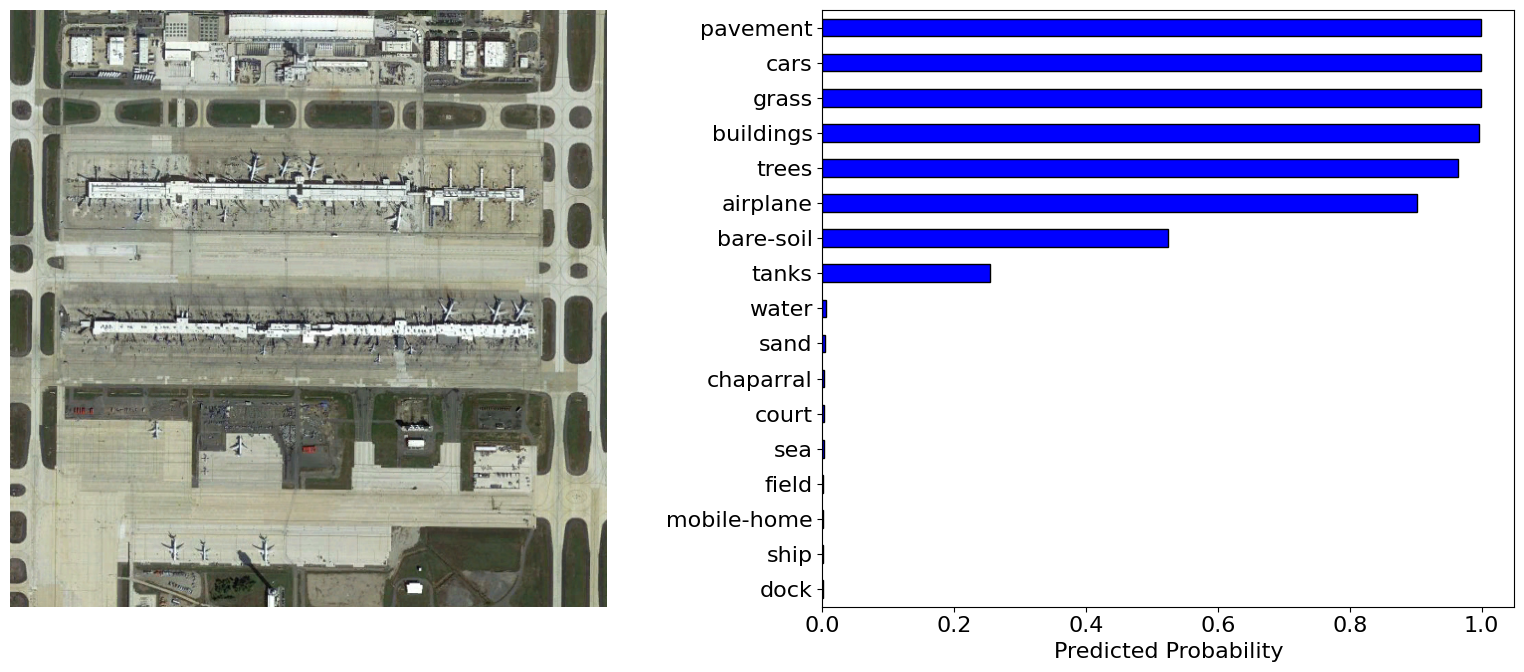

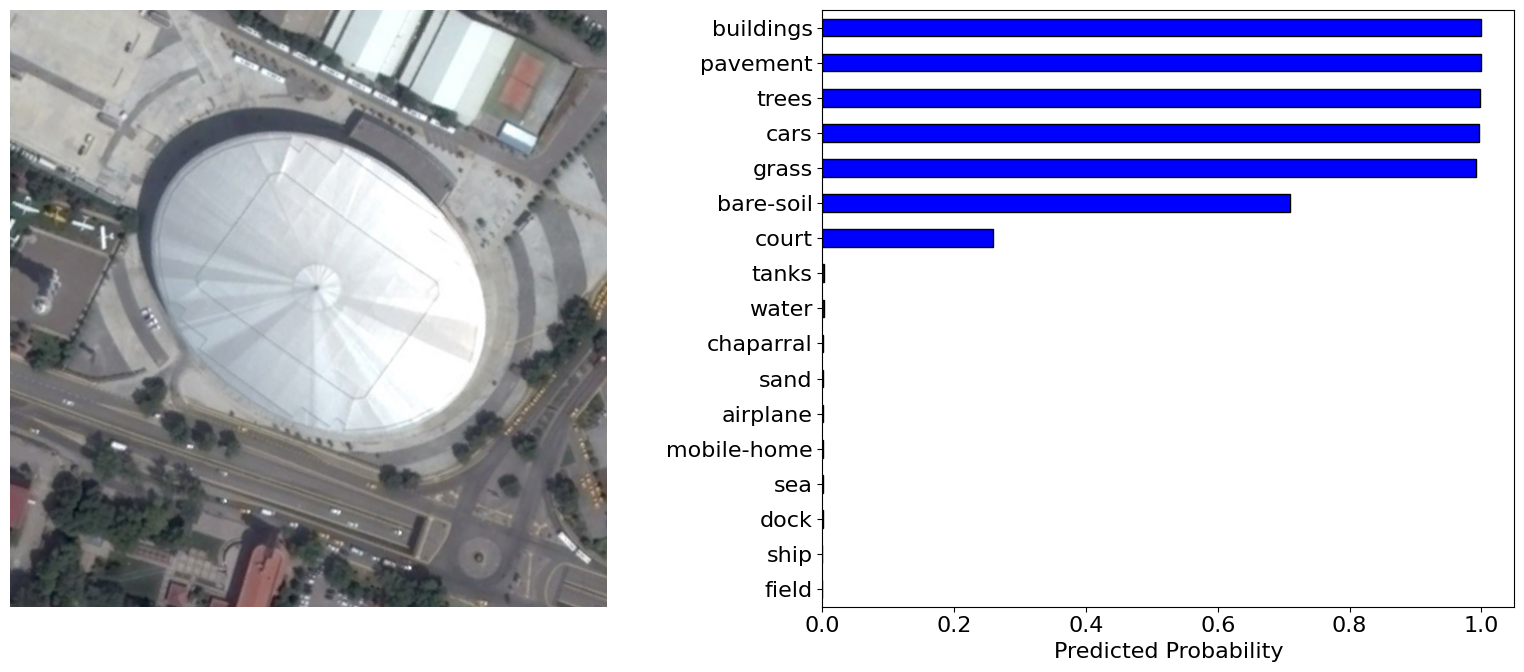

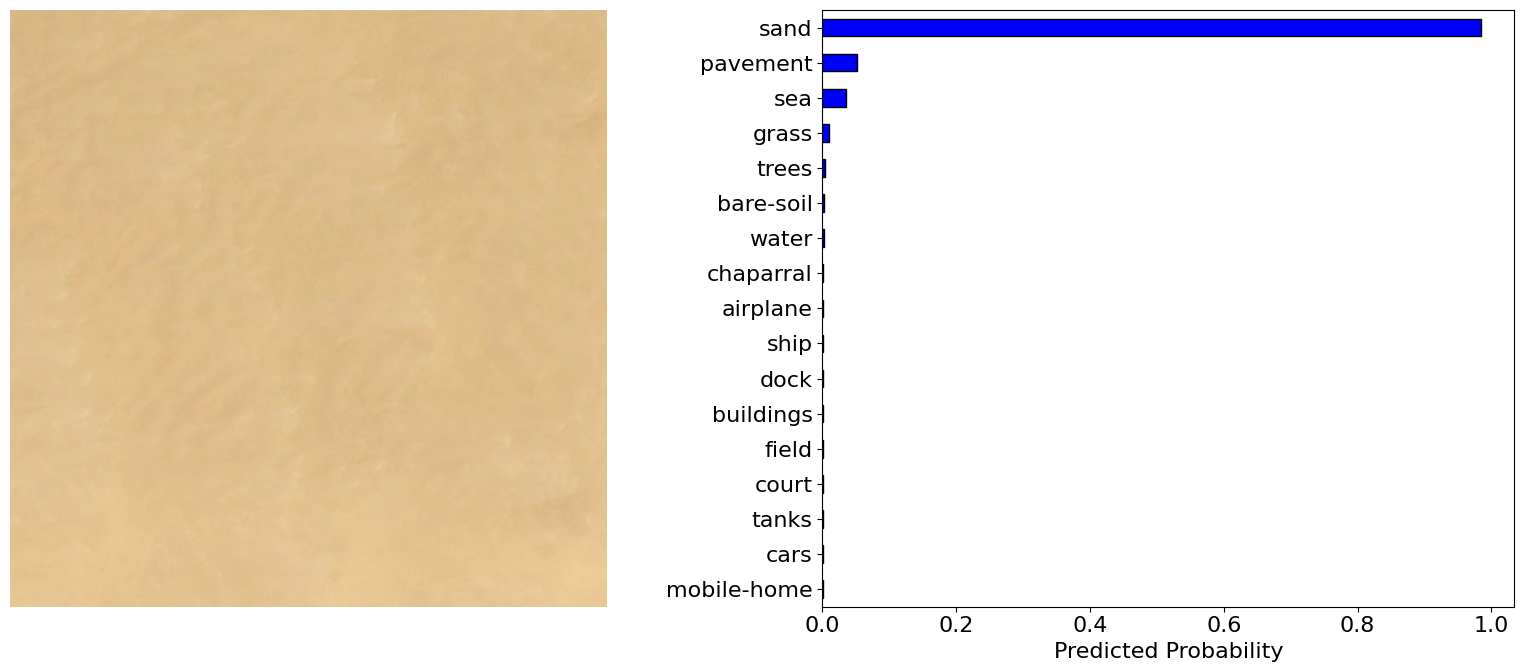

In [ ]:
model_path = "./data/experiments/AID_multilabel/checkpoint.pth.tar"
labels = [
    "airplane",
    "bare-soil",
    "buildings",
    "cars",
    "chaparral",
    "court",
    "dock",
    "field",
    "grass",
    "mobile-home",
    "pavement",
    "sand",
    "sea",
    "ship",
    "tanks",
    "trees",
    "water",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader("./data/AID_multilabel/test/images/airport_82.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/AID_multilabel/test/images/center_99.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/AID_multilabel/test/images/desert_87.jpg")
fig = model.predict_image(image, labels, transform)